# HW3 Part 01 - Data Exploration with Descriptive Statistics and Visualizations

TOTAL POINT: 50


**Objective of this Exercise**

In class, we discussed the importance of exploratory data analysis (EDA) and effective visualization. The goal is to conduct EDA on the Boston Housing Price dataset using Python, following an EDA checklist. You will explore the data, ask relevant questions, and analyze variation and covariation. Visualize your findings with a focus on good visualization practices, attention theory, and visual salience. Additionally, perform a brief feature engineering exercise.

## Data for this exercise

We use the boston house price data in this exercise. The data is available as part of ```sklearn``` for [Python](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.datasets). The description of the data is provided together with the actual data and should be the starting point for your analysis of the data.

## TASK 01 Descriptive statistics of the boston data (POINT: 02)

**TASK 1.1:** Explore the boston data using descriptive statistics. Calculate the central tendency with the mean and median, the variability through the standard deviation and the IQR, as well as the range of the data. The real task is understanding something about the data from these results. For example, what can you learn about the CRIM feature from the mean and the median?

In [1]:
import pandas as pd
from sklearn import datasets

# # first we load the data and print description
# boston = datasets.load_boston()
# print(boston.DESCR)

from sklearn.datasets import fetch_openml

boston = fetch_openml(name='boston', version=1)
X, y = boston.data, boston.target
print(boston.DESCR)

# we convert the data into a data frame and use the convenient describe function from pandas
boston_df = pd.DataFrame(boston.data, columns=boston.feature_names)

# write your one line code for  descriptive statistics

boston_df.describe()

**Author**:   
**Source**: Unknown - Date unknown  
**Please cite**:   

The Boston house-price data of Harrison, D. and Rubinfeld, D.L. 'Hedonic
prices and the demand for clean air', J. Environ. Economics & Management,
vol.5, 81-102, 1978.   Used in Belsley, Kuh & Welsch, 'Regression diagnostics
...', Wiley, 1980.   N.B. Various transformations are used in the table on
pages 244-261 of the latter.
Variables in order:
CRIM     per capita crime rate by town
ZN       proportion of residential land zoned for lots over 25,000 sq.ft.
INDUS    proportion of non-retail business acres per town
CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
NOX      nitric oxides concentration (parts per 10 million)
RM       average number of rooms per dwelling
AGE      proportion of owner-occupied units built prior to 1940
DIS      weighted distances to five Boston employment centres
RAD      index of accessibility to radial highways
TAX      full-value property-tax rate per $10

,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,TAX,PTRATIO,B,LSTAT
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.554695,6.284634,68.574901,3.795043,408.237154,18.455534,356.674032,12.653063
std,8.601545,23.322453,6.860353,0.115878,0.702617,28.148861,2.105710,168.537116,2.164946,91.294864,7.141062
min,0.006320,0.000000,0.460000,0.385000,3.561000,2.900000,1.129600,187.000000,12.600000,0.320000,1.730000
25%,0.082045,0.000000,5.190000,0.449000,5.885500,45.025000,2.100175,279.000000,17.400000,375.377500,6.950000
50%,0.256510,0.000000,9.690000,0.538000,6.208500,77.500000,3.207450,330.000000,19.050000,391.440000,11.360000
75%,3.677083,12.500000,18.100000,0.624000,6.623500,94.075000,5.188425,666.000000,20.200000,396.225000,16.955000
max,88.976200,100.000000,27.740000,0.871000,8.780000,100.000000,12.126500,711.000000,22.000000,396.900000,37.970000


Some things we can learn from the summary statistics:
- The mean of CRIM is much larger than the median (50%). The together with the very large max value this is a strong indicator that the distribution is not symmetric around the mean and likely as a long right-tail. Since the median is close the the minimal value, this also indicates that a lot of data is located in a small region on the left side of the distribution. Together with the description of the data, this means that there are many regions with a low crime rate and a relatively small portion of regions has a higher crime rate.
- The data indicates that RM is likely symmetric around the mean. This is indicated because the mean and the median are roughly equal, and the distance from the lower quartile (25%) is similar to the distance of the upper quartile (75%) from the median. Whether RM follows a gaussian distribution cannot be evaluated without statistical tests or at least a visualization. Given that this feature models the number of rooms, it also makes sense that the data is not dominated by outliers.
- CHAS seems to have a strange distribution, because the min and the upper quartile of the same value of 0. This fits the description that this is just a dummy variable used as control.

## TASK 2: Ask Right Question (POINTS: 2+2+2=6)

You are now going to ask two questions.

**Remember** that the first question will focus on variation using a chosen variable. The second question will explore covariation, using **one variable from the first question** and another variable. After formulating the questions, you will plot the results.

**TASK 2.1:** Show all the columns of the dataset

In [2]:
# Show all the columns first

boston_df.columns

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT'],
      dtype='object')


### Question 1: Variation

**TASK 2.2:** Write a question and include a one-line explanation of why it is an important question.


**Your Question:** How does the CRIM variable vary per town?

**Importance:** I find this important because a high variation in crime rate per town could lead to discovering the variables that are potentially causing the disparity in crime rate.


### Question 2: Covariation

**TASK 2.2:** Write a question and include a one-line explanation of why it is an important question.


**Your Question:** Is there a relationship between the CRIM and TAX variables?

**Importance:** There's a possibility that high or low property-tax rates could affect the conditions of a town leading to a difference in per capita crime rate.

# TASK 03: Data Analysis Part 01 (1+2+(2+3)+2=10)


### Question 01 Visualization

Now, for your above Question 01 on Variation: Create a plot to show the distribution of the variable you have chosen and visualize its variation. Remember to make it visually appealing (this applies to every plot in this exercise).

*** TASK 3.1: Write in one line: the variable(s) name that you are plotting below.***

CRIM

**TASK 3.2:** Create a plot to show the distribution of the variable you have chosen for Question 01 and visualize its variation.

Text(0, 0.5, 'Frequency')

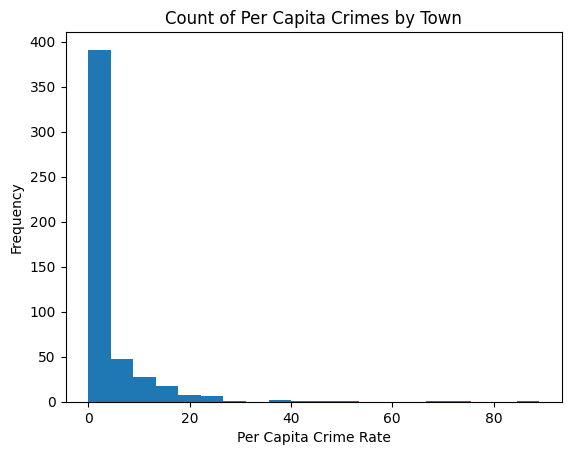

In [3]:
#plot here. Import necessary libraries if needed.
import matplotlib.pyplot as plt
import seaborn as sns


# Plotting the distribution of your chosen variable
plt.hist(boston_df['CRIM'], bins = 20)
plt.title('Count of Per Capita Crimes by Town')
plt.xlabel('Per Capita Crime Rate')
plt.ylabel('Frequency')


### Question 02 Covariation

Now,
* **TASK 3.3:**Calculate the correlation between the two variables you chose in Question 2.Provide an brief interpretation of the correlation coefficient.

After that, you have to plot the relationship between these two variables.

In [4]:
# Write Code

# Calculate the correlation between the variables
correlation = boston_df['CRIM'].corr(boston_df['TAX'])
print(f"corr: {correlation}\n")

# Interpretation

print("There appears to be a moderate positive linear correlation between the CRIM and TAX variables")


corr: 0.5827643120325852

There appears to be a moderate positive linear correlation between the CRIM and TAX variables


**TASK 3.4:** Plot the relationship between these two variables.

Text(0, 0.5, 'Full Value Property-tax Rate per $10,000')

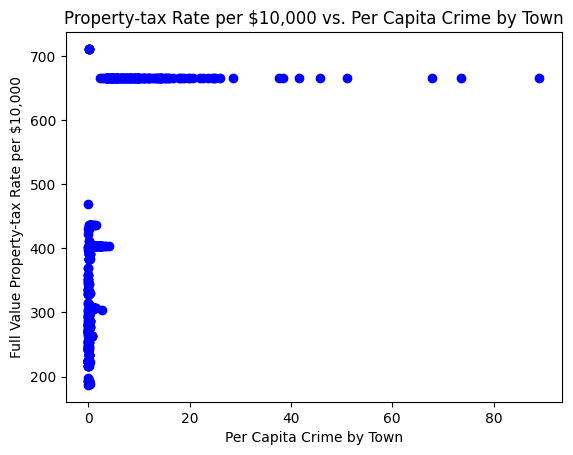

In [5]:
# Plotting the relationship between these two variables

plt.scatter(x=boston_df['CRIM'], y=boston_df['TAX'], color='blue')
plt.title('Property-tax Rate per $10,000 vs. Per Capita Crime by Town')
plt.xlabel('Per Capita Crime by Town')
plt.ylabel('Full Value Property-tax Rate per $10,000')

# TASK 04: Understanding Data Types and Visualization (POINTS: 1+1+5+2+1+4+4=18)

Understanding data types is important! Your next task is to choose any **categorical variable** from the dataset.
* Display a table showing both the frequency and relative frequency of that variable.
* Finally, create a plot to visualize the distribution of the categorical variable

## Categorical Data Analysis

**TASK 4.1**: Display the data types of each column in the dataset

In [6]:
# Display the data types of each column in boston_df

boston_df.dtypes

,0
CRIM,float64
ZN,float64
INDUS,float64
CHAS,category
NOX,float64
RM,float64
AGE,float64
DIS,float64
RAD,category
TAX,float64


**TASK 4.2:** Write down the name of the categorial variable that you have chosen:***

CHAS

**TASK 4.3**: Display a table showing both the frequency and relative frequency of that variable.

In [7]:
# Frequency and relative frequency for your chosen categorical variable
cat_var = 'CHAS'
freq = boston_df[cat_var].value_counts()
rel_freq = boston_df[cat_var].value_counts(normalize=True)

# Create a table for frequency and relative frequency
freq_table = pd.DataFrame({'Frequency': freq, "Relative_Frequency": rel_freq})

# Print the frequency and relative frequency table for the categorial variable
print(freq_table)

      Frequency  Relative_Frequency
CHAS                               
0           471             0.93083
1            35             0.06917


**TASK 4.4**: Create a plot to visualize the distribution of the categorical variable

Text(0, 0.5, 'Frequency')

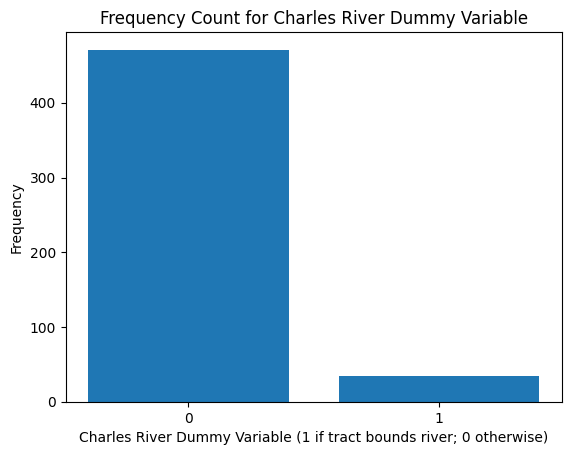

In [8]:
# Plotting the categorical variable:
sorted_freq = freq.sort_index()
plt.bar(sorted_freq.index, sorted_freq.values)
plt.title('Frequency Count for Charles River Dummy Variable')
plt.xlabel('Charles River Dummy Variable (1 if tract bounds river; 0 otherwise)')
plt.ylabel('Frequency')

## Binning Continuous Data

How can you categorize any two continuous variables from the dataset into discrete bins?
Your next task is:
*  Use an appropriate binning method to create categories, and
* then visualize the distribution of these categories to enhance your understanding of the data.

*** TASK 4.5: Write down the name of the two continous variables that you have chosen:***

ZN and INDUS

**TASK 4.6**: Use an appropriate binning method to create categories for two continuous variables of your choice from the dataset.

In [9]:


# Binning the continuous variables:
# Create bins for first continuous variable and print
ZN_label = ['(0, 10]', '(10, 20]', '(20, 30]', '(30, 40]', '(40, 50]', '(50, 60]', '(60, 70]', '(70, 80]', '(80, 90]', '(90, 100]']
ZN_bins = pd.cut(boston_df['ZN'], bins=10, labels=ZN_label)
print(f"ZN bins: {sorted(ZN_bins.unique())}")

# Create bins for second continous variable and print
INDUS_edges = [0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30]
INDUS_label = ['(0, 3]', '(3, 6]', '(6, 9]', '(9, 12]', '(12, 15]', '(15, 18]', '(18, 21]', '(21, 24]', '(24, 27]', '(27, 30]']
INDUS_bins = pd.cut(boston_df['INDUS'], bins=INDUS_edges, labels=INDUS_label)
print(f"INDUS bins: {sorted(INDUS_bins.unique())}")


ZN bins: ['(0, 10]', '(10, 20]', '(20, 30]', '(30, 40]', '(40, 50]', '(50, 60]', '(60, 70]', '(70, 80]', '(80, 90]', '(90, 100]']
INDUS bins: ['(0, 3]', '(12, 15]', '(15, 18]', '(18, 21]', '(21, 24]', '(24, 27]', '(27, 30]', '(3, 6]', '(6, 9]', '(9, 12]']


**TASK 4.7**: Visualize the distribution of these binned categories to enhance your understanding of the data.

Text(0, 0.5, 'Frequency')

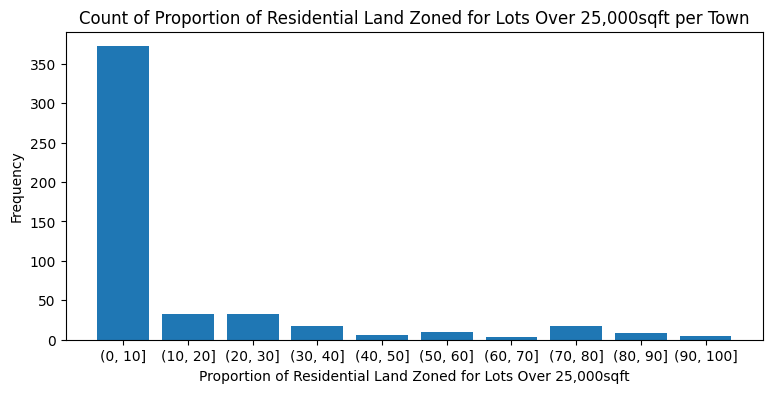

In [10]:
# Visualize the distribution of first binned variable
ZN_freq = ZN_bins.value_counts().sort_index()

plt.figure(figsize=(9, 4))

plt.bar(ZN_freq.index, ZN_freq.values)
plt.title('Count of Proportion of Residential Land Zoned for Lots Over 25,000sqft per Town')
plt.xlabel('Proportion of Residential Land Zoned for Lots Over 25,000sqft')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

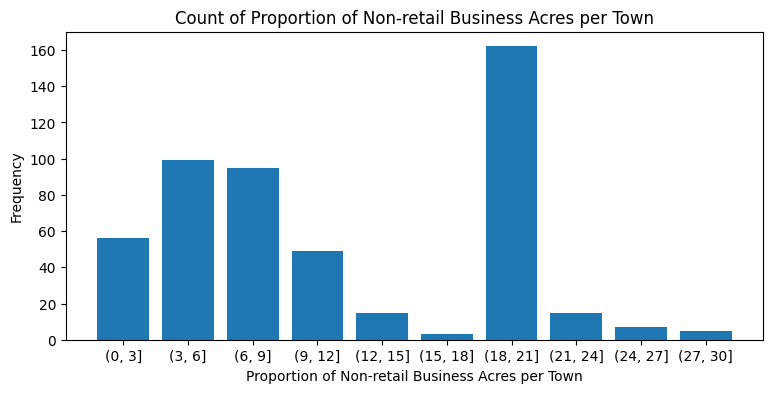

In [11]:
# Visualize the distribution of second binned variable
INDUS_freq = INDUS_bins.value_counts().sort_index()

plt.figure(figsize=(9, 4))

plt.bar(INDUS_freq.index, INDUS_freq.values)
plt.title('Count of Proportion of Non-retail Business Acres per Town')
plt.xlabel('Proportion of Non-retail Business Acres per Town')
plt.ylabel('Frequency')

# TASK 05: Good Visualizations: StoryTelling, Attention and Valiance (POINTS: 4+3=7)

The Python library ```matplotlib``` is great for creating all kinds of visualizations. There are even libraries on top of ```matplotlib``` that facilitate relatively complex visualizations in a single line of code like ```seaborn```.


**Task 5.1:** Create an impactful visualization that effectively communicates a key relationship within the dataset. You can use any variables you want, or you can also perform feature engineering by adding or modifying any variable.

Text(0, 0.5, 'Weighted Distance from 5 Boston Employement Centers')

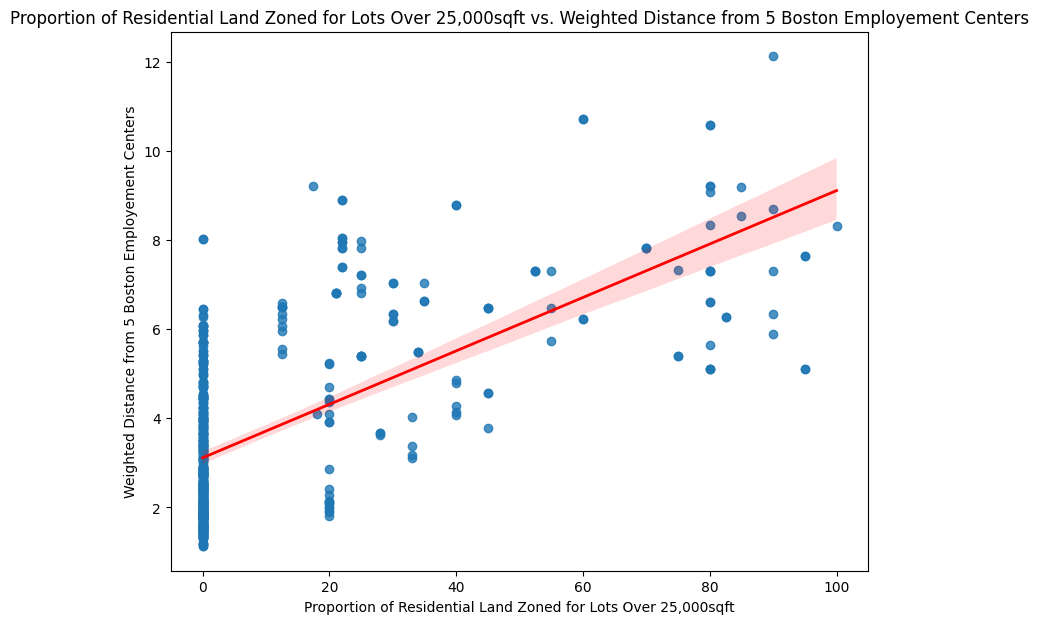

In [12]:
# Plot the Visualization.
plt.figure(figsize=(9, 7))

sns.regplot(data=boston_df, x='ZN', y='DIS', line_kws={"color": "red", "linewidth": 2})

plt.title('Proportion of Residential Land Zoned for Lots Over 25,000sqft vs. Weighted Distance from 5 Boston Employement Centers')
plt.xlabel('Proportion of Residential Land Zoned for Lots Over 25,000sqft')
plt.ylabel('Weighted Distance from 5 Boston Employement Centers')

**Task 5.2:** Now, Explain how you apply principles of visual attention and salience to enhance the viewer's understanding of this relationship and the story it tells.

#Answer here

Story and Visual Attention:
I decided to add a regression line in order to highlight a potential positive correlation between the variables ZN and DIS. I decided to make the regression line a bright red contrasting with the blue of the points to make it catch the attention of the viewer immediately. The line so also makes it easy to notice the trend of the distance from the employment centers increasing as the proportion of resident land increases.

# TASK 06: Missing Data Check, Outlier Detection and Feature Engineering (POINTS: 2+2+1+2= 07)


**TASK 6.1:** Check for missing values in the dataset

In [13]:
# Check for missing values
boston_df.isna().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


**TASK 6.2:** Check for outliers for RM Variable in the dataset

{'whiskers': [<matplotlib.lines.Line2D at 0x7fa27837a490>,
 'caps': [<matplotlib.lines.Line2D at 0x7fa27837a710>,
 'boxes': [<matplotlib.lines.Line2D at 0x7fa27a5ca850>],
 'medians': [<matplotlib.lines.Line2D at 0x7fa27837a990>],
 'fliers': [<matplotlib.lines.Line2D at 0x7fa27837aad0>],
 'means': []}

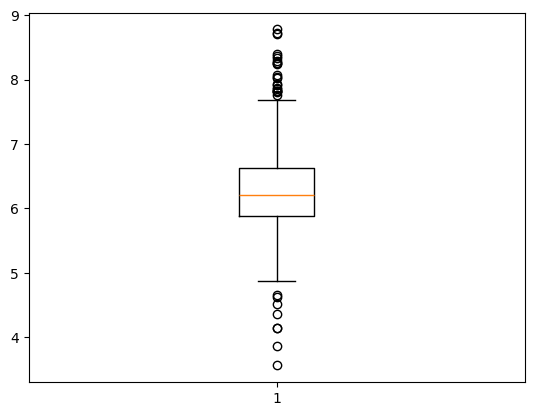

In [14]:

# Create a box plot for RM to detect outliers
plt.boxplot(boston_df['RM'])


**TASK 6.3:** Is there any outlier?

ANSWER:
Yes there appears to be both high and low outliers

**TASK 6.4:** Create a new feature by calculating the ratio of the average number of rooms (RM) to the percentage of lower status of the population (LSTAT).

In [15]:
# Creating a new feature: RM to LSTAT ratio
boston_df['LRM'] = boston_df['RM'] / boston_df['LSTAT']


# Display modified DataFrame (only head)
boston_df.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,LRM
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,1.320281
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,0.702516
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,1.782878
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,2.380272
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,1.340901
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,1.234165
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,0.483669
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,0.322298
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,0.188139
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,0.351111


# THE END of HW1 Part 01